In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [7]:
from sklearn.model_selection import RepeatedStratifiedKFold, GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    roc_auc_score, recall_score, precision_score, f1_score, confusion_matrix
)
from sklearn.calibration import calibration_curve
import xgboost as xgb


In [8]:
RANDOM_STATE = 42
df= pd.read_csv("C:/Users/786/Downloads/vaccination_data.csv")

df["incomplete_vaccination"] = df["incomplete_vaccination"].map({"Complete": 0, "Incomplete": 1})

In [9]:
outcome = "incomplete_vaccination"


all_predictors = [
    "Sex_of_child_cat", "Region_cat", "Residence", "Wealth_index_cat",
    "Education_level", "Place_of_delivery_cat", "Marital_status_cat",
    "Employment_status_cat", "Freq_of_listening2Radio_cat",
    "Age_of_child", "Birth_order", "Age_of_mother", "No_of_ANC_visits",
    "No_of_household_members", "Parity", "Preeceding_birth_interval_months"
]

X = df[all_predictors]
y = df[outcome]

numeric_vars = X.select_dtypes(include=["int64", "float64"]).columns.tolist()
categorical_vars = X.select_dtypes(include=["object"]).columns.tolist()

print("Detected NUMERIC columns:", numeric_vars)
print("Detected CATEGORICAL columns:", categorical_vars)
 
print(f"Sample size: {len(df)}")
print(f"Outcome distribution:\n{y.value_counts(normalize=True).round(3)}\n")
 


Detected NUMERIC columns: ['Age_of_child', 'Birth_order', 'Age_of_mother', 'No_of_household_members', 'Parity', 'Preeceding_birth_interval_months']
Detected CATEGORICAL columns: ['Sex_of_child_cat', 'Region_cat', 'Residence', 'Wealth_index_cat', 'Education_level', 'Place_of_delivery_cat', 'Marital_status_cat', 'Employment_status_cat', 'Freq_of_listening2Radio_cat', 'No_of_ANC_visits']
Sample size: 278
Outcome distribution:
incomplete_vaccination
0    0.529
1    0.471
Name: proportion, dtype: float64



C:\Users\786\AppData\Local\Temp\ipykernel_22944\1405532337.py:16: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_vars = X.select_dtypes(include=["object"]).columns.tolist()


In [10]:
from sklearn.impute import SimpleImputer

preprocessor = ColumnTransformer([
    ("cat", Pipeline([
        ("impute", SimpleImputer(strategy="most_frequent")),
        ("encode", OneHotEncoder(handle_unknown="ignore"))
    ]), categorical_vars),
    
    ("num", Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("scale", StandardScaler())
    ]), numeric_vars)
])
 

In [11]:
log_reg = Pipeline([
    ("prep", preprocessor),
    ("clf", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
])
 
rf = Pipeline([
    ("prep", preprocessor),
    ("clf", RandomForestClassifier(random_state=RANDOM_STATE))
])
 
xgb_clf = Pipeline([
    ("prep", preprocessor),
    ("clf", xgb.XGBClassifier(eval_metric="logloss", random_state=RANDOM_STATE))
])
 

In [12]:
rf_param_grid = {
    "clf__n_estimators": [100, 200],
    "clf__max_depth": [3, 5, None],
    "clf__min_samples_leaf": [1, 5, 10]
}

xgb_param_grid = {
    "clf__n_estimators": [100, 200],
    "clf__max_depth": [3, 4, 5],
    "clf__learning_rate": [0.01, 0.1]
}


In [13]:
rf_grid = GridSearchCV(rf, rf_param_grid, cv=3, scoring="roc_auc", n_jobs=-1)
xgb_grid = GridSearchCV(xgb_clf, xgb_param_grid, cv=3, scoring="roc_auc", n_jobs=-1)
 
models = {
    "Logistic Regression": log_reg,
    "Random Forest": rf_grid,
    "XGBoost": xgb_grid
}
 

In [14]:
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=RANDOM_STATE)

In [15]:
def sensitivity(y_true, y_pred):
    return recall_score(y_true, y_pred, pos_label=1)

def ppv(y_true, y_pred):
    return precision_score(y_true, y_pred, pos_label=1, zero_division=0)

def f1(y_true, y_pred):
    return f1_score(y_true, y_pred, pos_label=1, zero_division=0)




def specificity(y_true, y_pred):
    """Of children TRULY complete, what % did we correctly clear?"""
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    return tn / (tn + fp) if (tn + fp) > 0 else np.nan

 
def npv(y_true, y_pred):
    """Negative predictive value: of children we CLEARED as complete, what % truly are?"""
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    return tn / (tn + fn) if (tn + fn) > 0 else np.nan

In [16]:
raw_scores = {name: {"AUC": [], "Sensitivity": [], "Specificity": [],
                      "PPV": [], "NPV": [], "F1": []} for name in models}
 
for name, model in models.items():
    print(f"Running {name} ...")
    for train_idx, test_idx in cv.split(X, y):
        X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
        y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
 
        model.fit(X_train, y_train)                       # fit/tune on training fold only
        y_pred = model.predict(X_test)                     # predict on held-out fold
        y_prob = model.predict_proba(X_test)[:, 1]         # predicted probability of "incomplete"
 
        raw_scores[name]["AUC"].append(roc_auc_score(y_test, y_prob))
        raw_scores[name]["Sensitivity"].append(sensitivity(y_test, y_pred))
        raw_scores[name]["Specificity"].append(specificity(y_test, y_pred))
        raw_scores[name]["PPV"].append(ppv(y_test, y_pred))
        raw_scores[name]["NPV"].append(npv(y_test, y_pred))
        raw_scores[name]["F1"].append(f1_score(y_test, y_pred, zero_division=0))
 
print("\nDone.\n")

Running Logistic Regression ...
Running Random Forest ...
Running XGBoost ...

Done.



In [17]:
summary_rows = []
for name, metrics in raw_scores.items():
    row = {"Model": name}
    for metric_name, values in metrics.items():
        row[f"{metric_name}_mean"] = np.mean(values)
        row[f"{metric_name}_sd"] = np.std(values)
    summary_rows.append(row)
 
results_df = pd.DataFrame(summary_rows).set_index("Model").round(3)
print(results_df)
results_df.to_csv("objective3_model_comparison.csv")
 
readable = pd.DataFrame(index=results_df.index)
for metric_name in ["AUC", "Sensitivity", "Specificity", "PPV", "NPV", "F1"]:
    readable[metric_name] = (
        results_df[f"{metric_name}_mean"].round(3).astype(str)
        + " ± "
        + results_df[f"{metric_name}_sd"].round(3).astype(str)
    )
print("\nFormatted for write-up:\n")
print(readable)
readable.to_csv("objective3_model_comparison_readable.csv")

                     AUC_mean  AUC_sd  Sensitivity_mean  Sensitivity_sd  \
Model                                                                     
Logistic Regression     0.539   0.062             0.483           0.106   
Random Forest           0.578   0.072             0.429           0.102   
XGBoost                 0.601   0.061             0.497           0.084   

                     Specificity_mean  Specificity_sd  PPV_mean  PPV_sd  \
Model                                                                     
Logistic Regression             0.576           0.081     0.503   0.070   
Random Forest                   0.719           0.096     0.584   0.097   
XGBoost                         0.659           0.100     0.571   0.075   

                     NPV_mean  NPV_sd  F1_mean  F1_sd  
Model                                                  
Logistic Regression     0.558   0.062    0.490  0.081  
Random Forest           0.587   0.048    0.488  0.085  
XGBoost                 


Calibration plot saved to objective3_calibration_plot.png


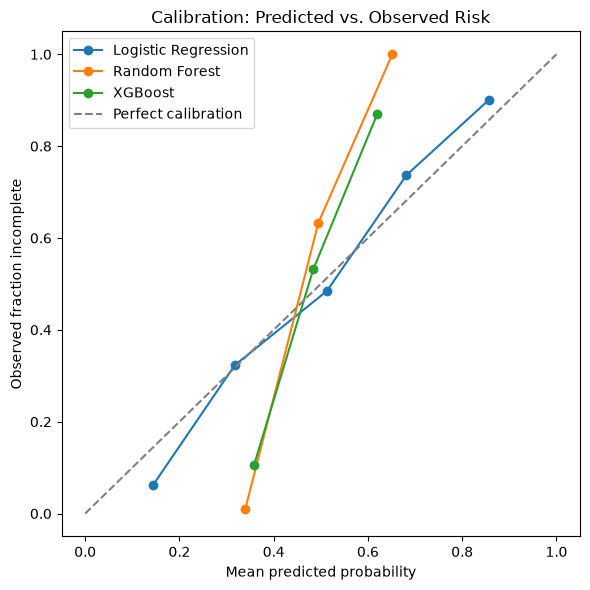

In [18]:
fig, ax = plt.subplots(figsize=(6, 6))
for name, model in models.items():
    model.fit(X, y)
    y_prob = model.predict_proba(X)[:, 1]
    frac_pos, mean_pred = calibration_curve(y, y_prob, n_bins=5)
    ax.plot(mean_pred, frac_pos, marker="o", label=name)
 
ax.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Perfect calibration")
ax.set_xlabel("Mean predicted probability")
ax.set_ylabel("Observed fraction incomplete")
ax.set_title("Calibration: Predicted vs. Observed Risk")
ax.legend()
plt.tight_layout()
plt.savefig("objective3_calibration_plot.png", dpi=300)
print("\nCalibration plot saved to objective3_calibration_plot.png")

Testing calibration for Logistic Regression ...
Testing calibration for Random Forest ...
Testing calibration for XGBoost ...
                 Model Version    AUC  Brier  Cal. slope  Cal. intercept
0  Logistic Regression  Before  0.528  0.280       0.109          -0.100
1  Logistic Regression   After  0.478  0.251      -0.069          -0.125
2        Random Forest  Before  0.574  0.244       0.971          -0.006
3        Random Forest   After  0.514  0.249       0.599          -0.009
4              XGBoost  Before  0.626  0.241       0.573          -0.037
5              XGBoost   After  0.493  0.253      -0.007          -0.116

Reference Brier score (always predicting the average): 0.249


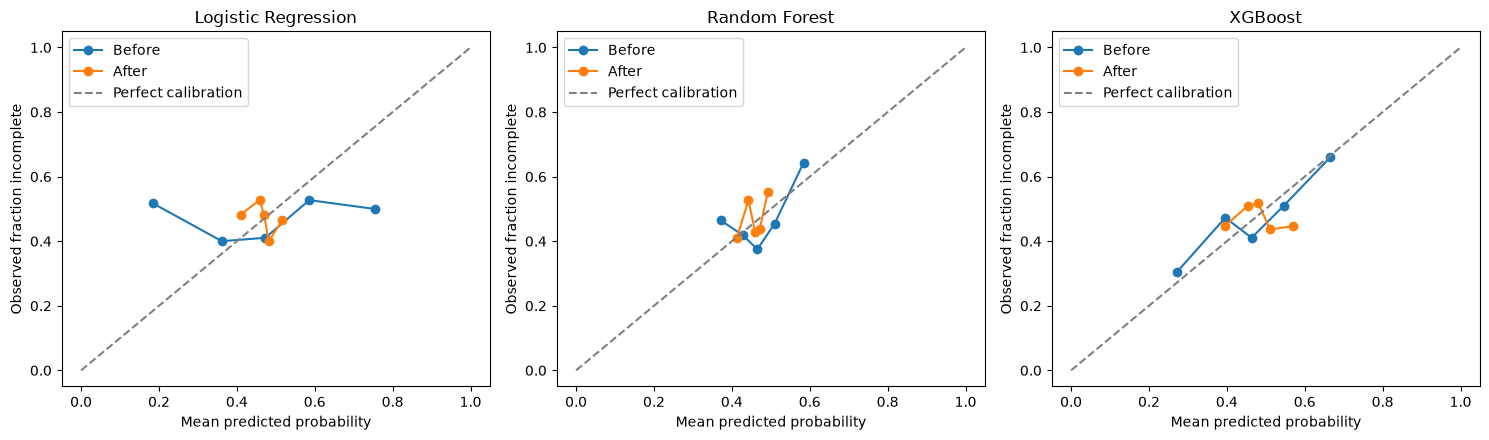

In [ ]:
from sklearn.base import clone
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import brier_score_loss, roc_auc_score
from sklearn.linear_model import LogisticRegression

cal_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

def slope_intercept(y_true, p):
    """Calibration slope (ideal = 1) and intercept (ideal = 0)."""
    p = np.clip(p, 1e-6, 1 - 1e-6)
    logit = np.log(p / (1 - p)).reshape(-1, 1)
    lr = LogisticRegression(C=1e6, max_iter=1000).fit(logit, y_true)
    return lr.coef_[0][0], lr.intercept_[0]

oof, rows = {}, []
for name, model in models.items():
    print(f"Testing calibration for {name} ...")

    # Before: tuned model, out-of-fold probabilities
    p_raw = cross_val_predict(clone(model), X, y, cv=cal_cv, method="predict_proba")[:, 1]

    # After: Platt (sigmoid) calibration wrapped around the same model (tuning repeats inside each fold)
    cal_model = CalibratedClassifierCV(clone(model), method="sigmoid", cv=3)
    p_cal = cross_val_predict(cal_model, X, y, cv=cal_cv, method="predict_proba")[:, 1]

    oof[name] = (p_raw, p_cal)
    for label, p in [("Before", p_raw), ("After", p_cal)]:
        s, i = slope_intercept(y, p)
        rows.append({"Model": name, "Version": label,
                     "AUC": roc_auc_score(y, p),
                     "Brier": brier_score_loss(y, p),
                     "Cal. slope": s, "Cal. intercept": i})

cal_results = pd.DataFrame(rows).round(3)
print(cal_results)
print("\nReference Brier score (always predicting the average):",
      round(y.mean() * (1 - y.mean()), 3))
cal_results.to_csv("objective3_calibration_results.csv", index=False)


fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, (name, (p_raw, p_cal)) in zip(axes, oof.items()):
    for p, label in [(p_raw, "Before"), (p_cal, "After")]:
        frac_pos, mean_pred = calibration_curve(y, p, n_bins=5, strategy="quantile")
        ax.plot(mean_pred, frac_pos, marker="o", label=label)
    ax.plot([0, 1], [0, 1], "--", color="gray", label="Perfect calibration")
    ax.set_title(name)
    ax.set_xlabel("Mean predicted probability")
    ax.set_ylabel("Observed fraction incomplete")
    ax.legend()
plt.tight_layout()
plt.savefig("objective3_calibration_plot_cv.png", dpi=300)
plt.show()

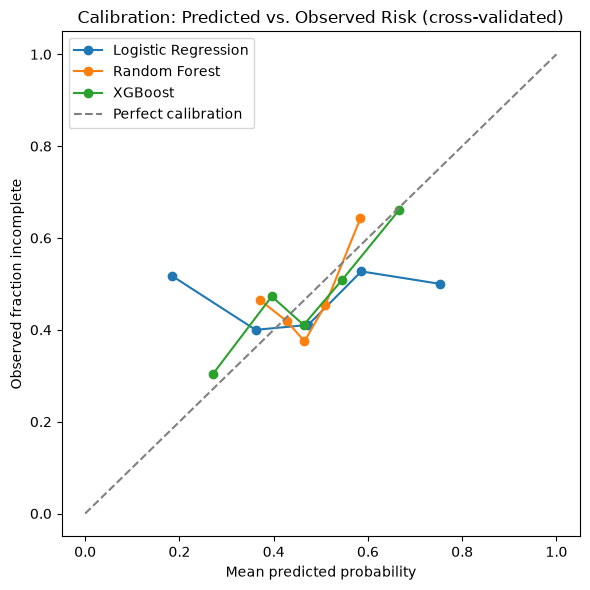

In [20]:
fig, ax = plt.subplots(figsize=(6, 6))
for name, (p_raw, p_cal) in oof.items():
    frac_pos, mean_pred = calibration_curve(y, p_raw, n_bins=5, strategy="quantile")
    ax.plot(mean_pred, frac_pos, marker="o", label=name)
ax.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Perfect calibration")
ax.set_xlabel("Mean predicted probability")
ax.set_ylabel("Observed fraction incomplete")
ax.set_title("Calibration: Predicted vs. Observed Risk (cross-validated)")
ax.legend()
plt.tight_layout()
plt.savefig("objective3_calibration_plot_cv.png", dpi=300)
plt.show()